# Chapitre 1 - Exercices 1.1 à 1.5

Ces exercices portent sur la première moitié du chapitre (section *The Rise of AI
Engineering*) : tokens, auto-supervision, types de modèles de langage.

- **1.1** : la « taxe » linguistique des tokens (comparaison de tokenizers et impact sur
  la facture) ;
- **1.2** : construire un BPE à la main, puis vérifier avec le code ;
- **1.3** : découper un texte en paires auto-supervisées (autorégressif, fenêtre de
  contexte, masqué) et comparer le signal d'apprentissage ;
- **1.4** : le coût de l'étiquetage face à l'auto-supervision (calculs d'ordres de
  grandeur) ;
- **1.5** : masqué ou autorégressif ? (raisonnement, puis mini-lab sur deux vrais modèles).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from aie.plotting import INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT, annotate_bars, finish
from aie.diagrams import Diagram
from aie import llm
from aie import ch01_introduction as c1

c1.setup_style()
rng = np.random.default_rng(0)
pd.set_option("display.max_colwidth", 100)

## Exercice 1.1 : La taxe linguistique des tokens

**Énoncé.** Une entreprise exploite un assistant en anglais qui génère en moyenne
2 millions de tokens de sortie par jour (cl100k, tokenizer de GPT-4), facturés 10 $ par
million. Elle veut lancer la même application en français, à volume de **contenu**
identique.

1. À l'aide du corpus parallèle `c1.PARALLEL_EN_FR` (8 phrases anglais / français),
   estimer pour chaque tokenizer le ratio $r = n_{\text{FR}} / n_{\text{EN}}$ du nombre de
   tokens, avec une idée de sa variabilité d'une phrase à l'autre.
2. En déduire le surcoût mensuel (30 jours) de la version française avec cl100k, puis avec
   o200k (en supposant le même prix par token).
3. Pourquoi ce ratio dépend-il du tokenizer ? Que faudrait-il vérifier avant de conclure ?

**Rappels.** Le token est l'unité de facturation (cours 1, section 4, et section
*Language models* du livre). Un tokenizer BPE est appris sur un corpus : les mots
fréquents dans ce corpus deviennent des tokens uniques, les mots rares sont découpés. Le
coût d'une requête est $\text{coût} = (n_{\text{in}} p_{\text{in}} + n_{\text{out}} p_{\text{out}})/10^6$.

**Solution.**

*1. Ratios.* On tokenise chaque phrase dans les deux langues et on calcule le ratio du
nombre total de tokens, ainsi que les ratios phrase par phrase pour juger de la
dispersion.

In [2]:
rows = []
for name in c1.TOKENIZERS:
    tk = c1.get_tokenizer(name)
    en = np.array([tk.count(e) for e, _ in c1.PARALLEL_EN_FR])
    fr = np.array([tk.count(f) for _, f in c1.PARALLEL_EN_FR])
    rows.append({"tokenizer": name, "tokens EN": en.sum(), "tokens FR": fr.sum(),
                 "ratio global": fr.sum() / en.sum(), "ratio min (phrase)": (fr / en).min(),
                 "ratio max (phrase)": (fr / en).max(), "_ratios": fr / en})
tab = pd.DataFrame(rows).set_index("tokenizer")
w_ratio = sum(len(c1.words(f)) for _, f in c1.PARALLEL_EN_FR) / sum(len(c1.words(e)) for e, _ in c1.PARALLEL_EN_FR)
print(f"Pour référence, ratio du nombre de MOTS français / anglais : {w_ratio:.2f}")
tab.drop(columns="_ratios").round(2)

Pour référence, ratio du nombre de MOTS français / anglais : 1.15


,tokens EN,tokens FR,ratio global,ratio min (phrase),ratio max (phrase)
tokenizer,,,,,
GPT-2,80,149,1.86,1.67,2.18
GPT-4 (cl100k),76,121,1.59,1.33,2.00
GPT-4o (o200k),74,99,1.34,1.11,1.80
Qwen2.5,76,121,1.59,1.33,2.00
XLM-R,94,111,1.18,0.92,2.00


*2. Surcoût.* Si l'anglais coûte $C_{\text{EN}} = 2 \times 30 \times 10 = 600$ $ par mois,
le français coûte $r \cdot C_{\text{EN}}$, soit un surcoût de $(r - 1) \cdot 600$ $.

In [3]:
base_cost = 2 * 30 * 10.0
for name in ["GPT-4 (cl100k)", "GPT-4o (o200k)", "GPT-2"]:
    r = tab.loc[name, "ratio global"]
    print(f"{name:16s} r = {r:.2f} -> version FR : {r * base_cost:7.0f} $/mois, surcoût {(r - 1) * base_cost:+6.0f} $ ({r - 1:+.0%})")

GPT-4 (cl100k)   r = 1.59 -> version FR :     955 $/mois, surcoût   +355 $ (+59%)
GPT-4o (o200k)   r = 1.34 -> version FR :     803 $/mois, surcoût   +203 $ (+34%)
GPT-2            r = 1.86 -> version FR :    1118 $/mois, surcoût   +518 $ (+86%)


*3. Interprétation.* Une partie du surcoût n'a rien à voir avec le tokenizer : la
traduction française de nos phrases contient environ 15 % de mots de plus que l'anglais
(articles, prépositions, apostrophes comptées comme coupures). Même un tokenizer
« parfait » donnerait donc un ratio supérieur à 1. Au-delà, le ratio dépend de la
**composition du corpus d'apprentissage** du tokenizer : un vocabulaire appris sur un web majoritairement anglophone (GPT-2) contient
peu de sous-mots français, d'où un découpage plus fin. Les vocabulaires plus grands et plus
multilingues (o200k, XLM-R) ramènent le ratio près de celui des mots. Avant de conclure, il faut vérifier sur des
textes **représentatifs** de l'application (vocabulaire métier, longueur, ponctuation), car
8 phrases courtes donnent une estimation grossière : la dispersion phrase à phrase le
montre. Il faut aussi tenir compte du fait que la **qualité** du modèle peut elle-même
différer selon la langue. $\blacksquare$

**Vérification graphique** : distribution des ratios phrase par phrase.

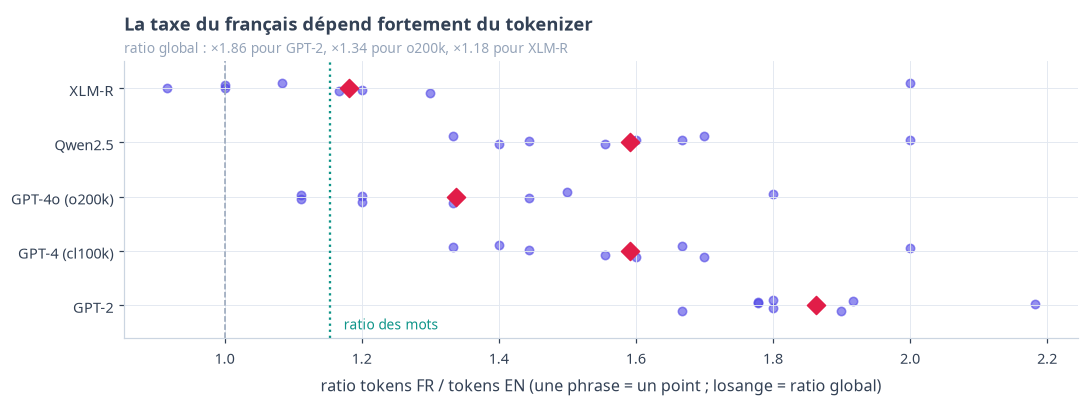

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
names = list(tab.index)
for i, n in enumerate(names):
    rr = tab.loc[n, "_ratios"]
    ax.scatter(rr, np.full(len(rr), i) + rng.uniform(-0.12, 0.12, len(rr)), color=INDIGO, alpha=0.6, s=30)
    ax.scatter([tab.loc[n, "ratio global"]], [i], color=ROSE, marker="D", s=70, zorder=5)
ax.axvline(1, color=GRAY, ls="--", lw=1)
ax.set_yticks(range(len(names)), names)
ax.set_xlabel("ratio tokens FR / tokens EN (une phrase = un point ; losange = ratio global)")
ax.axvline(w_ratio, color=TEAL, ls=":", lw=1.5)
ax.text(w_ratio + 0.02, -0.45, "ratio des mots", color=TEAL, fontsize=9)
ax.set_ylim(-0.6, len(names) - 0.5)
c1.title_sub(ax, "La taxe du français dépend fortement du tokenizer",
             f"ratio global : ×{tab.loc['GPT-2', 'ratio global']:.2f} pour GPT-2, ×{tab.loc['GPT-4o (o200k)', 'ratio global']:.2f} "
             f"pour o200k, ×{tab.loc['XLM-R', 'ratio global']:.2f} pour XLM-R")
plt.tight_layout(); plt.show()

> **À retenir.** À contenu égal, une application en français peut coûter (et durer) de
> 20 % à près de 90 % de plus qu'en anglais selon le tokenizer, dont une part incompressible
> due à la longueur du texte français lui-même. Mesurez le ratio sur vos propres textes,
> avec le tokenizer du modèle visé, avant de chiffrer un projet.

## Exercice 1.2 : Construire un BPE à la main

**Énoncé.** On considère le mini-corpus (avec fréquences) :
« bas » ×4, « basse » ×3, « bassin » ×2, « base » ×2, « rasé » ×1. Chaque mot est suivi du
marqueur de fin de mot « _ ».

1. Dérouler à la main les **trois premières fusions** de l'algorithme BPE (en cas
   d'égalité, choisir la paire la plus petite dans l'ordre lexicographique).
2. Donner la tokenisation de « basé » et de « bassine » après ces trois fusions.
3. Vérifier avec `c1.train_bpe` et `c1.bpe_tokenize`, puis tracer, pour le corpus du
   dépôt, le nombre moyen de tokens par mot en fonction du nombre de fusions.

**Rappels.** BPE (cours 1, section 3) : partir des caractères, compter les paires de
symboles adjacents (pondérées par la fréquence des mots), fusionner la plus fréquente,
recommencer. Chaque fusion ajoute exactement un symbole au vocabulaire.

**Solution.**

*Étape 1.* Comptons quelques paires (fréquence du mot × occurrences dans le mot) :

| paire | bas (4) | basse (3) | bassin (2) | base (2) | rasé (1) | total |
|---|---|---|---|---|---|---|
| (b, a) | 4 | 3 | 2 | 2 | 0 | **11** |
| (a, s) | 4 | 3 | 2 | 2 | 1 | **12** |
| (s, _) | 4 | 0 | 0 | 0 | 0 | 4 |
| (s, s) | 0 | 3 | 2 | 0 | 0 | 5 |
| (e, _) | 0 | 3 | 0 | 2 | 0 | 5 |

La paire la plus fréquente est **(a, s)** avec 12 occurrences : on crée « as ».

*Étape 2.* Les mots deviennent b·as·_, b·as·s·e·_, b·as·s·i·n·_, b·as·e·_, r·as·é·_. La paire
(b, as) apparaît 4 + 3 + 2 + 2 = **11** fois, devant (as, s) = 5, (e, _) = 5 : on crée
« bas ».

*Étape 3.* Mots : bas·_, bas·s·e·_, bas·s·i·n·_, bas·e·_, r·as·é·_. Paires candidates :
(bas, s) = 5, (e, _) = 5, (bas, _) = 4, (s, e) = 3... Égalité à 5 entre (bas, s) et (e, _) :
dans l'ordre lexicographique « bas » < « e », on fusionne **(bas, s)** en « bass ».

*Tokenisations.* On applique les fusions dans l'ordre : « basé » donne b·a·s·é·_ puis
b·as·é·_ puis **bas·é·_** (la fusion « bass » ne s'applique pas). « bassine » donne
**bass·i·n·e·_**. $\blacksquare$

**Vérification** avec le code du module.

In [5]:
corpus = ["bas"] * 4 + ["basse"] * 3 + ["bassin"] * 2 + ["base"] * 2 + ["rasé"]
m3 = c1.train_bpe(corpus, 3)
print("fusions :", m3)
for w in ["basé", "bassine"]:
    print(f"{w:8s} ->", c1.bpe_tokenize(w, m3))

fusions : [('a', 's'), ('b', 'as'), ('bas', 's')]
basé     -> ['bas', 'é', '_']
bassine  -> ['bass', 'i', 'n', 'e', '_']


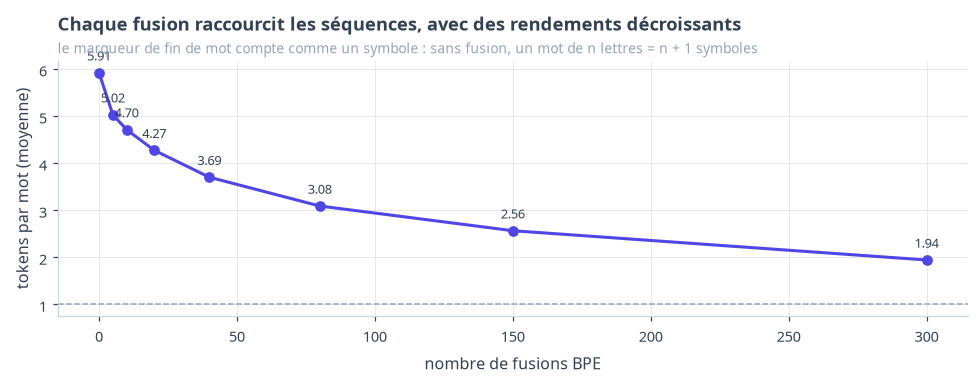

In [6]:
corpus_words = c1.words(c1.CORPUS_FR.lower())
all_m = c1.train_bpe(corpus_words, 300)
grid = [0, 5, 10, 20, 40, 80, 150, 300]
tpw = [np.mean([len(c1.bpe_tokenize(w, all_m[:k])) for w in corpus_words]) for k in grid]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(grid, tpw, "o-", color=INDIGO)
for k, v in zip(grid, tpw):
    ax.annotate(f"{v:.2f}", (k, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5)
ax.axhline(1, color=GRAY, ls="--", lw=1)
ax.set_xlabel("nombre de fusions BPE"); ax.set_ylabel("tokens par mot (moyenne)")
c1.title_sub(ax, "Chaque fusion raccourcit les séquences, avec des rendements décroissants",
             "le marqueur de fin de mot compte comme un symbole : sans fusion, un mot de n lettres = n + 1 symboles")
plt.tight_layout(); plt.show()

Les premières fusions (paires très fréquentes) font chuter rapidement la longueur ; les
suivantes ne concernent que des suites de plus en plus rares, d'où des gains décroissants.
Les tokenizers réels poursuivent jusqu'à 50 000 à 250 000 symboles sur des corpus
gigantesques.

> **À retenir.** BPE est un algorithme glouton simple : fusionner la paire adjacente la plus
> fréquente, encore et encore. Un mot inconnu se décompose toujours avec les fusions
> apprises, et le nombre de fusions règle le compromis vocabulaire / longueur.

## Exercice 1.3 : Découper un texte en paires auto-supervisées

**Énoncé.** On prend la phrase « Le modèle prédit le prochain token . » découpée en
7 mots.

1. Combien de paires (contexte, cible) un modèle autorégressif en tire-t-il avec `<BOS>`
   et `<EOS>` ? Les lister.
2. Même question avec une **fenêtre de contexte** limitée à 3 tokens. Qu'est-ce qui
   change, et pourquoi est-ce un problème pour la cible « token » ?
3. Pour un modèle **masqué** (15 % des tokens masqués), combien de cibles une séquence de
   $n$ tokens fournit-elle par passe ? Comparer le « signal » par passe avec le cas
   autorégressif pour $n$ allant de 10 à 2 000, et commenter.

**Rappels.** Section *Self-supervision* du livre et cours 2, section 2 : chaque position
d'une séquence fournit une cible, son contexte étant ce qui précède ; `<EOS>` apprend au
modèle à s'arrêter. Un modèle masqué (BERT) ne prédit que les positions masquées
(≈ 15 %).

**Solution.**

*1.* Une séquence de $n = 7$ tokens encadrée par `<BOS>` et `<EOS>` donne $n + 1 = 8$
paires : chaque token, plus `<EOS>`, sert une fois de cible.

In [7]:
phrase = ["Le", "modèle", "prédit", "le", "prochain", "token", "."]
c1.pairs_table(c1.autoregressive_pairs(phrase))

,entrée (contexte),sortie (prochain token)
0,<BOS>,Le
1,<BOS> Le,modèle
2,<BOS> Le modèle,prédit
3,<BOS> Le modèle prédit,le
4,<BOS> Le modèle prédit le,prochain
5,<BOS> Le modèle prédit le prochain,token
6,<BOS> Le modèle prédit le prochain token,.
7,<BOS> Le modèle prédit le prochain token .,<EOS>


*2.* Avec une fenêtre de 3 tokens, on a toujours 8 paires, mais les contextes sont
**tronqués** aux 3 derniers tokens. Pour prédire « token », le modèle ne voit plus que
« prédit le prochain » : il perd « Le modèle », qui rend « token » bien plus probable
(on parle de modèle ici). Les dépendances à longue distance deviennent inaccessibles :
c'est pourquoi la longueur de contexte est une caractéristique clé des LLM (chapitre 2).

In [8]:
c1.pairs_table(c1.autoregressive_pairs(phrase, max_context=3))

,entrée (contexte),sortie (prochain token)
0,<BOS>,Le
1,<BOS> Le,modèle
2,<BOS> Le modèle,prédit
3,Le modèle prédit,le
4,modèle prédit le,prochain
5,prédit le prochain,token
6,le prochain token,.
7,prochain token .,<EOS>


*3.* Un modèle masqué à 15 % fournit environ $0{,}15\,n$ cibles par passe, contre $n$ (ou
$n+1$) pour un modèle autorégressif : à données égales, l'autorégressif reçoit environ
**6,7 fois plus de signal d'apprentissage** par passe. En contrepartie, chaque cible du
modèle masqué bénéficie du contexte bilatéral. Ce rendement supérieur est l'une des raisons
(avec la capacité de générer) de la domination des modèles autorégressifs. $\blacksquare$

**Vérification** numérique avec `c1.masked_pairs` sur une phrase réelle tokenisée par GPT-2,
puis graphique.

210 tokens -> 211 cibles autorégressives, 32 cibles masquées
extrait masqué : Le matin, la[MASK][MASK] se réveille lentement. Les b[MASK]angers ont allumé leurs four[MASK][MASK]ien avant


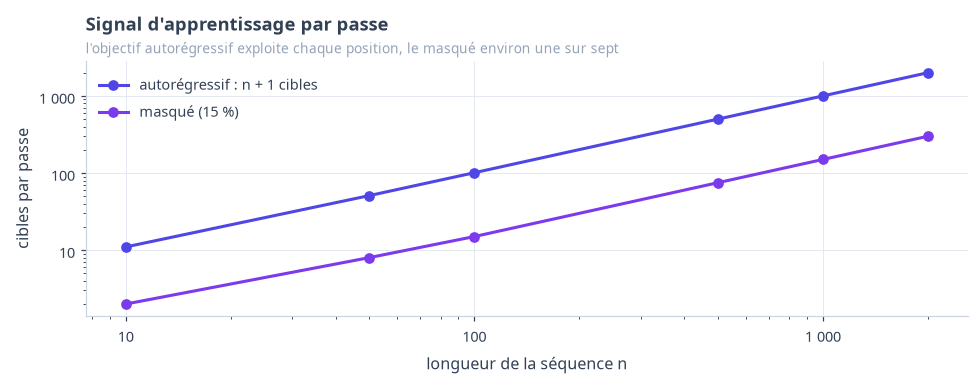

In [9]:
tok = c1.get_tokenizer("GPT-2")
text = c1.CORPUS_FR[:600]
pieces = tok.pieces(text)
masked, targets = c1.masked_pairs(pieces, rate=0.15, seed=1)
print(f"{len(pieces)} tokens -> {len(c1.autoregressive_pairs(pieces))} cibles autorégressives, "
      f"{len(targets)} cibles masquées")
print("extrait masqué :", "".join(masked[:30]).replace("<MASK>", "[MASK]"))

ns = np.array([10, 50, 100, 500, 1000, 2000])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(ns, ns + 1, "o-", color=INDIGO, label="autorégressif : n + 1 cibles")
ax.plot(ns, [len(c1.masked_pairs(list(range(n)), 0.15)[1]) for n in ns], "o-", color=VIOLET, label="masqué (15 %)")
ax.set_xscale("log"); ax.set_yscale("log"); c1.plain_log(ax, "x"); c1.plain_log(ax, "y")
ax.set_xlabel("longueur de la séquence n"); ax.set_ylabel("cibles par passe")
ax.legend()
c1.title_sub(ax, "Signal d'apprentissage par passe", "l'objectif autorégressif exploite chaque position, le masqué environ une sur sept")
plt.tight_layout(); plt.show()

> **À retenir.** Un texte de $n$ tokens donne $n+1$ exemples autorégressifs (tous traités en
> une passe), mais seulement ≈ $0{,}15n$ exemples masqués. La fenêtre de contexte ne change
> pas le nombre d'exemples, mais limite l'information disponible pour chacun.